<a href="https://colab.research.google.com/github/keikezon/FIAP-IA-para-devs/blob/master/EEG_chb01_03.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

--2026-11-08 02:45:12--  https://physionet.org/files/chbmit/1.0.0/chb01/chb01_03.edf
Resolving physionet.org (physionet.org)... 18.25.8.254
Connecting to physionet.org (physionet.org)|18.25.8.254|:443... connected.
HTTP request sent, awaiting response... 302 Found
Location: https://physionet-open.s3.amazonaws.com/chbmit/1.0.0/chb01/chb01_03.edf [following]
--2026-11-08 02:45:13--  https://physionet-open.s3.amazonaws.com/chbmit/1.0.0/chb01/chb01_03.edf
Resolving physionet-open.s3.amazonaws.com (physionet-open.s3.amazonaws.com)... 52.216.95.126, 52.217.120.26, 54.231.195.234, ...
Connecting to physionet-open.s3.amazonaws.com (physionet-open.s3.amazonaws.com)|52.216.95.126|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 42399744 (40M) [binary/octet-stream]
Saving to: ‘chb01_03.edf’

chb01_03.edf        100%[===================>]  40.44M  9.95MB/s    in 4.1s    

2026-11-08 02:45:18 (9.95 MB/s) - ‘chb01_03.edf’ saved [42399744/42399744]

Extracting EDF parameters 

/tmp/ipykernel_3034/1371847898.py:11: RuntimeWarning: Channel names are not unique, found duplicates for: {'T8-P8'}. Applying running numbers for duplicates.
  raw = mne.io.read_raw_edf('chb01_03.edf', preload=True)


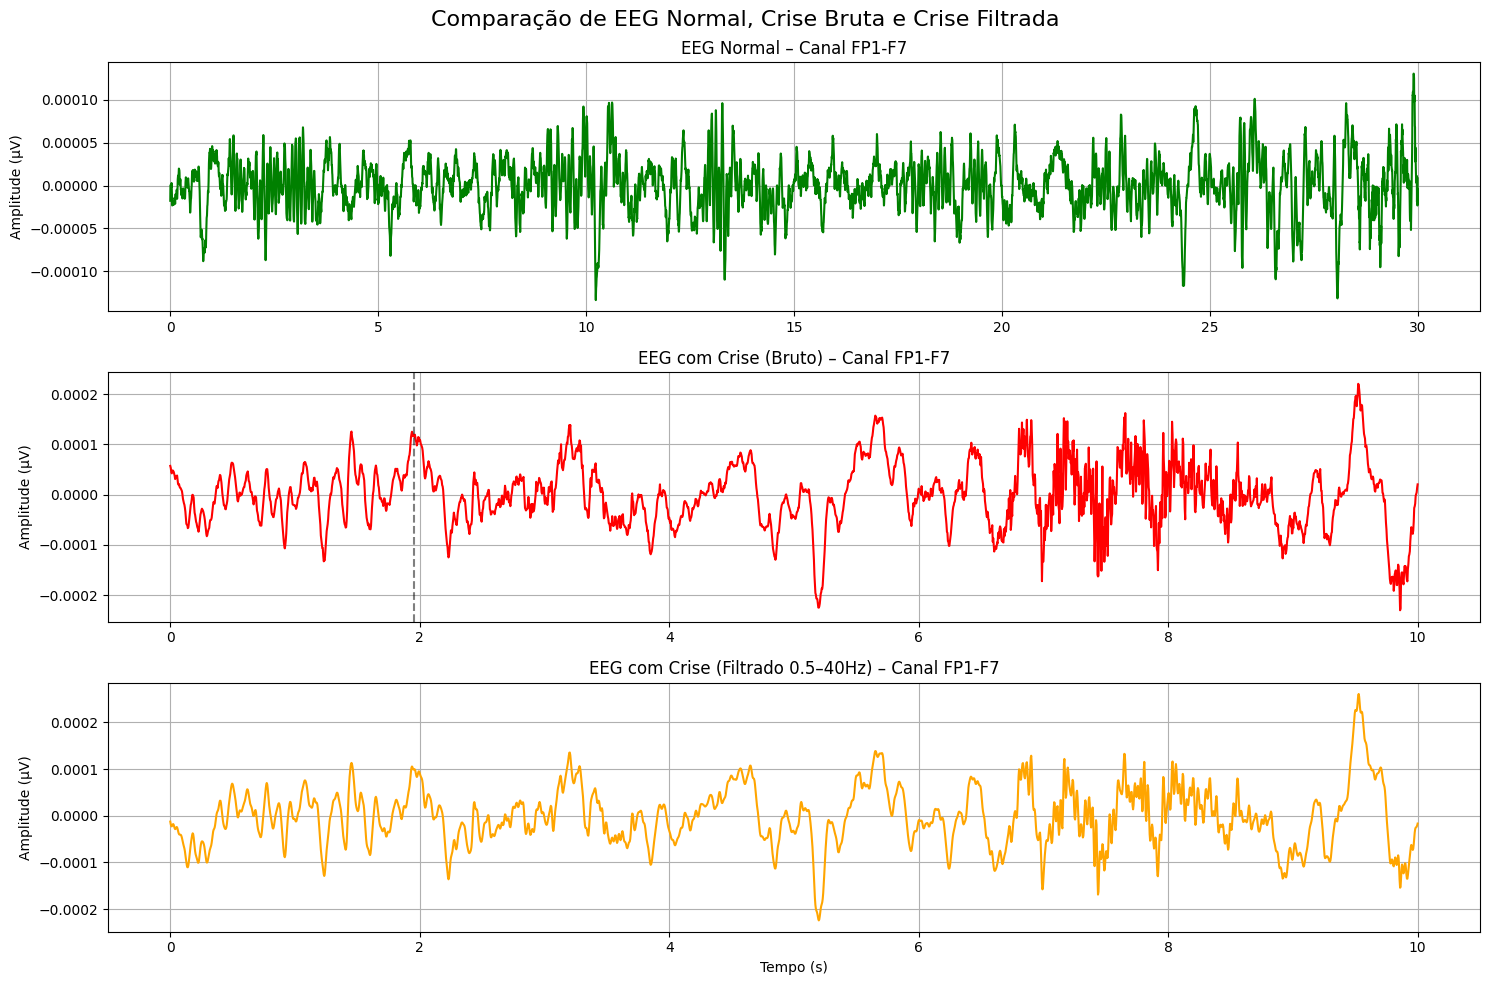


--- Iniciando Treinamento do Modelo de Classificação ---

Relatório de Classificação (Random Forest):
              precision    recall  f1-score   support

      Normal       1.00      1.00      1.00        17
       Crise       1.00      1.00      1.00        13

    accuracy                           1.00        30
   macro avg       1.00      1.00      1.00        30
weighted avg       1.00      1.00      1.00        30



In [14]:
!pip install mne -q
!pip install neurokit2 -q

import mne
import neurokit2 as nk
import matplotlib.pyplot as plt

# Carregar o EEG real
!wget -O chb01_03.edf https://physionet.org/files/chbmit/1.0.0/chb01/chb01_03.edf

raw = mne.io.read_raw_edf('chb01_03.edf', preload=True)

# Selecionar canal
canal_nome = "FP1-F7"
if canal_nome not in raw.ch_names:
    canal_nome = raw.ch_names[0]

# Taxa de amostragem
sfreq = int(raw.info['sfreq'])

# EEG normal (0–30s)
raw_normal = raw.copy().crop(tmin=0, tmax=30)
sinal_normal, tempo_normal = raw_normal[canal_nome]

# EEG com crise (2996–3006s)
raw_crise = raw.copy().crop(tmin=2996, tmax=3006)
sinal_crise, tempo_crise = raw_crise[canal_nome]

# Sinal filtrado (Butterworth 0.5–40Hz)
sinal_filtrado = nk.signal_filter(sinal_crise[0], sampling_rate=sfreq,
                                  lowcut=0.5, highcut=40, method='butterworth', order=5)

# Plotar os 3 sinais
plt.figure(figsize=(15, 10))

plt.subplot(3, 1, 1)
plt.plot(tempo_normal, sinal_normal[0], color='green')
plt.title(f"EEG Normal – Canal {canal_nome}")
plt.ylabel("Amplitude (µV)")
plt.grid(True)

plt.subplot(3, 1, 2)
plt.plot(tempo_crise, sinal_crise[0], color='red')
plt.title(f"EEG com Crise (Bruto) – Canal {canal_nome}")
plt.ylabel("Amplitude (µV)")
plt.axvline(x=tempo_crise[500], color='black', linestyle='--', alpha=0.5)
plt.grid(True)

plt.subplot(3, 1, 3)
plt.plot(tempo_crise, sinal_filtrado, color='orange')
plt.title(f"EEG com Crise (Filtrado 0.5–40Hz) – Canal {canal_nome}")
plt.xlabel("Tempo (s)")
plt.ylabel("Amplitude (µV)")
plt.grid(True)

plt.suptitle("Comparação de EEG Normal, Crise Bruta e Crise Filtrada", fontsize=16)
plt.tight_layout()
plt.show()

print("\n--- Iniciando Treinamento do Modelo de Classificação ---")

from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report
import numpy as np

# 1. Função para extrair características (Features) do sinal
# Em vez de passar o sinal bruto (milhares de pontos), passamos estatísticas resumidas
def extrair_features(sinal):
    return np.array([
        np.mean(sinal**2),       # Energia do sinal
        np.std(sinal),           # Desvio padrão (variabilidade)
        np.max(np.abs(sinal)),   # Amplitude máxima absoluta
        np.sum(np.abs(np.diff(sinal))) # Comprimento da linha (agitação)
    ])

# 2. Preparação dos Dados (Simulação de Data Augmentation)
# Como temos apenas 1 trecho de cada no exemplo anterior, vamos dividir esses trechos
# em pedaços menores para criar um "dataset" com vários exemplos para treino.

# Pega o array 1D dos sinais (o [0] é necessário pois o MNE retorna (1, N))
dados_normal = sinal_normal[0]
dados_crise = sinal_crise[0]

# Vamos criar 50 amostras de cada classe cortando pedaços aleatórios do sinal
X_normal = []
X_crise = []

janela = 1000 # tamanho do pedaço
for _ in range(50):
    # Pedaço aleatório do sinal normal
    inicio = np.random.randint(0, len(dados_normal) - janela)
    segmento = dados_normal[inicio:inicio+janela]
    X_normal.append(extrair_features(segmento))

    # Pedaço aleatório do sinal de crise
    inicio = np.random.randint(0, len(dados_crise) - janela)
    segmento = dados_crise[inicio:inicio+janela]
    X_crise.append(extrair_features(segmento))

X = np.array(X_normal + X_crise)
y = np.array([0] * 50 + [1] * 50) # 0 = Normal, 1 = Crise

# 3. Divisão Treino e Teste
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

# 4. Treinamento do Modelo
clf = RandomForestClassifier(n_estimators=100, random_state=42)
clf.fit(X_train, y_train)

# 5. Avaliação
y_pred = clf.predict(X_test)

print("\nRelatório de Classificação (Random Forest):")
print(classification_report(y_test, y_pred, target_names=['Normal', 'Crise']))